# 01 - Kiến thức và hiểu ngôn ngữ chung

**Đo cái gì?** Sáu bài kiểm tra chuẩn trên thế giới (MMLU, ARC-Easy, ARC-Challenge, HellaSwag, PIQA, WinoGrande) và IFEval (làm đúng chỉ dẫn).

**Vì sao cần?** Cho biết model có đủ 'nền tảng' để hiểu câu lệnh và ngữ cảnh. Đây là bộ thước đo mà hầu hết paper về model nhỏ đều báo cáo, nên có thể so với các nghiên cứu khác.

**Cách đọc biểu đồ:** Điểm là % câu trả lời đúng. Hầu hết bài là trắc nghiệm nên đoán bừa cũng được khoảng 25-50%; model chỉ có ý nghĩa khi điểm cao hơn mức đó rõ rệt.

**Giới hạn (để chuẩn bị phản biện):** Dùng lm-evaluation-harness với thiết lập mặc định và chỉ lấy một phần câu hỏi (xem `LIMITS`) để chạy kịp thời gian, nên điểm có sai số vài %; không dùng chat template nên IFEval thấp hơn con số công bố.

In [1]:
import os, torch
torch_lib = os.path.join(os.path.dirname(torch.__file__), "lib")
if os.path.isdir(torch_lib):
    os.add_dll_directory(torch_lib)
    if torch_lib not in os.environ.get("PATH", ""):
        os.environ["PATH"] = torch_lib + os.pathsep + os.environ.get("PATH", "")
import llama_cpp
print(llama_cpp.__version__, llama_cpp.llama_supports_gpu_offload())

ggml_cuda_init: found 1 CUDA devices (Total VRAM: 12281 MiB):
  Device 0: NVIDIA GeForce RTX 4070, compute capability 8.9, VMM: yes, VRAM: 12281 MiB


0.3.36 True


In [2]:
import llama_cpp
print(llama_cpp.__version__, llama_cpp.llama_supports_gpu_offload())

0.3.36 True


In [3]:
import slm_tools as st
import numpy as np
import pandas as pd

In [4]:
# số câu hỏi lấy cho mỗi bài (MMLU có 57 môn nên số này nhân với 57)
LIMITS = {"mmlu": 20, "arc_easy": 200, "arc_challenge": 200, "hellaswag": 200,
          "piqa": 200, "winogrande": 200, "ifeval": 100}

def measure(cfg):
    """Đo hiệu năng của mô hình với cấu hình cfg."""
    scores = st.lm_eval_scores(cfg, LIMITS)
    vals = [v for v in scores.values() if v is not None]
    scores["average"] = float(np.mean(vals)) if vals else 0.0
    return scores

Chạy ô này sẽ lần lượt bật từng model, đo, rồi lưu vào thư mục `results/`. Nếu bị ngắt giữa chừng, chạy lại: model nào đã xong sẽ được bỏ qua.

(Cần `pip install "lm_eval[ifeval]"` cho IFEval.)

In [ ]:
base_cfgs = st.base_configs()   # 1 dòng / model. Chấm trên trọng số HF GỐC, KHÔNG phải file GGUF Q8/Q4
# => điểm ở notebook này là điểm của model gốc, không dùng để so sánh các mức nén.
st.run_all("general_knowledge", measure, configs=base_cfgs, needs_server=False)

## Biểu đồ 1 - Model nào hiểu biết chung tốt nhất?

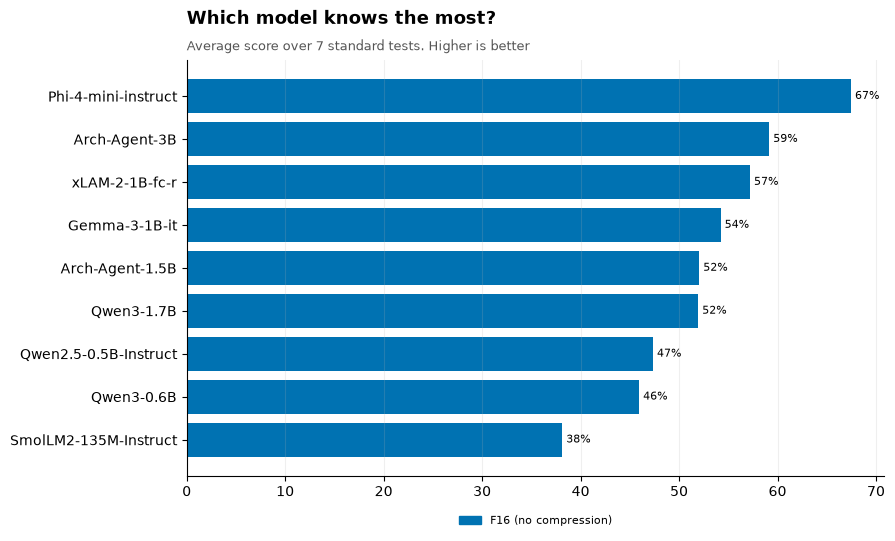

In [8]:
df = st.load_base("general_knowledge")
st.bar_chart(df, "average", "Which model knows the most?", "Average score over 7 standard tests. Higher is better",
             name="01_general_average")

## Biểu đồ 2 - Mạnh yếu ở bài nào? (đậm hơn = tốt hơn)

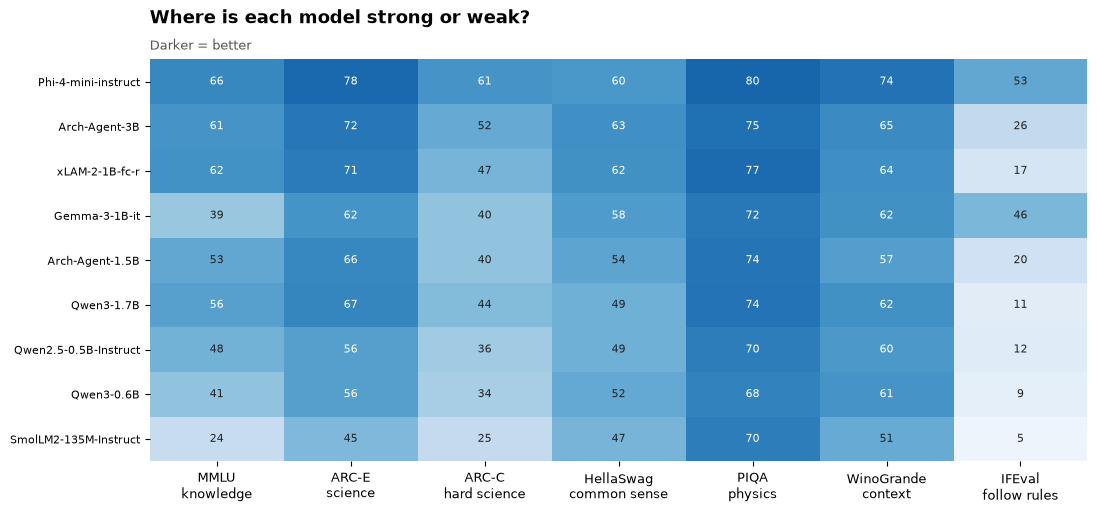

In [9]:
names = {"mmlu": "MMLU\nknowledge", "arc_easy": "ARC-E\nscience", "arc_challenge": "ARC-C\nhard science",
         "hellaswag": "HellaSwag\ncommon sense", "piqa": "PIQA\nphysics", "winogrande": "WinoGrande\ncontext",
         "ifeval": "IFEval\nfollow rules"}
st.heatmap(df, names, "Where is each model strong or weak?", name="01_general_heatmap")